In [ ]:
import os
import time
import random
import warnings

import matplotlib.pyplot as plt

import torch
import torchvision.models as models
import torchvision.transforms.functional as F

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner


random.seed(0)
warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Executorch version:  1.1.0


In [10]:
model_constructors = [
    models.segmentation.deeplabv3_resnet50,
    models.segmentation.deeplabv3_resnet101,
    models.segmentation.deeplabv3_mobilenet_v3_large,
    models.segmentation.lraspp_mobilenet_v3_large,
    models.segmentation.fcn_resnet50,
    models.segmentation.fcn_resnet101,
]
model_weights = [
    models.segmentation.DeepLabV3_ResNet50_Weights.DEFAULT,
    models.segmentation.DeepLabV3_ResNet101_Weights.DEFAULT,
    models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.LRASPP_MobileNet_V3_Large_Weights.DEFAULT,
    models.segmentation.FCN_ResNet50_Weights.DEFAULT,
    models.segmentation.FCN_ResNet101_Weights.DEFAULT,
]

In [11]:
# Resize size used for semantic segmentation models in torchvision, defined as
# `resize_size` parameter in `transforms` field of the `WeightsEnum` classes:
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_MobileNet_V3_Large_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/deeplabv3.html#DeepLabV3_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet101_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/fcn.html#FCN_ResNet50_Weights
# - https://docs.pytorch.org/vision/main/_modules/torchvision/models/segmentation/lraspp.html#LRASPP_MobileNet_V3_Large_Weights
RESIZE_SIZE = (520, 520)

# Directory to store the exported .pte files
EXPORT_DIR = "exports"

# Suffix for models
SUFFIX = "_xnnpack_fp32"

# Paths to the exported .pte files
MODEL_PATH: dict[str, str] = {}

# ImageNet mean and std for normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def preprocess(img: torch.Tensor):
    """
    Based on the definition of the `transforms` field in the `WeightsEnum`
    classes for our models (which is the same for every listed model that we
    export in this notebook and defined in `SemanticSegmentation` class here:
    https://github.com/pytorch/vision/blob/main/torchvision/transforms/_presets.py),
    except that we resize to the fixed size of 520x520 instead of resizing the
    image such that the shorter edge is 520 pixels and the longer edge is
    rescaled proportionally to the original aspect ratio.
    """
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)
    img = F.convert_image_dtype(img, torch.float)
    img = F.normalize(img, mean=IMAGENET_MEAN, std=IMAGENET_STD)
    return img


In [12]:
print("Exporting models...")

for constructor, weights in zip(model_constructors, model_weights):
    model = constructor(weights=weights).eval()
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    program = to_edge_transform_and_lower(export(model, inputs), partitioner=[XnnpackPartitioner()])
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/{constructor.__name__}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[constructor.__name__] = path
        f.write(program.buffer)

    print(f"Exported {MODEL_PATH[constructor.__name__]}\n")

Exporting models...
Exported exports/deeplabv3_resnet50_xnnpack_fp32.pte

Exported exports/deeplabv3_resnet101_xnnpack_fp32.pte

Exported exports/deeplabv3_mobilenet_v3_large_xnnpack_fp32.pte

Exported exports/lraspp_mobilenet_v3_large_xnnpack_fp32.pte

Exported exports/fcn_resnet50_xnnpack_fp32.pte

Exported exports/fcn_resnet101_xnnpack_fp32.pte



In [13]:
print("Verifying models...")

for constructor, weights in zip(model_constructors, model_weights):
    print(constructor.__name__.upper())
    path = MODEL_PATH[constructor.__name__]

    # --- ExecuTorch Inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = preprocess(img)
    print(img.shape)

    t = time.perf_counter()
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output, *_ = program.load_method("forward").execute([img])
    t = time.perf_counter() - t

    print(
        f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f}MB\n"
        f"Run successfully via ExecuTorch in {t:.2f} seconds."
    )

    # --- PyTorch Eager Reference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE, interpolation=F.InterpolationMode.BILINEAR, antialias=True)

    ref_model = constructor(weights=weights).eval()
    ref_output = ref_model(weights.transforms()(img))["out"]

    torch.testing.assert_close(output, ref_output, rtol=1e-3, atol=1e-4)
    print("Comparison passed!\n")

[program.cpp:154] InternalConsistency verification requested but not available
[

Verifying models...
DEEPLABV3_RESNET50
torch.Size([1, 3, 520, 520])


cpuinfo_utils.cpp:71] Reading file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:87] Failed to open midr file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:167] Number of efficient cores 4


Model size: 160.18MB
Run successfully via ExecuTorch in 2.02 seconds.


[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!

DEEPLABV3_RESNET101
torch.Size([1, 3, 520, 520])
Model size: 232.58MB
Run successfully via ExecuTorch in 2.38 seconds.


... (4 outputs left out)

[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!

FCN_RESNET50
torch.Size([1, 3, 520, 520])
Model size: 134.69MB
Run successfully via ExecuTorch in 1.64 seconds.


[program.cpp:154] InternalConsistency verification requested but not available


Comparison passed!

FCN_RESNET101
torch.Size([1, 3, 520, 520])
Model size: 207.09MB
Run successfully via ExecuTorch in 2.26 seconds.
Comparison passed!



Visual inspection...


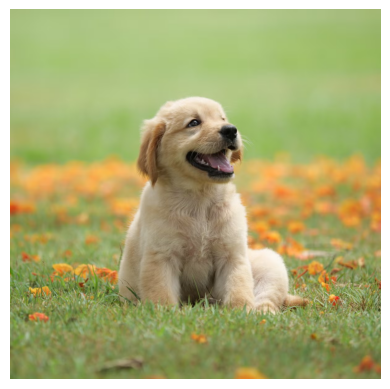

[program.cpp:154] InternalConsistency verification requested but not available


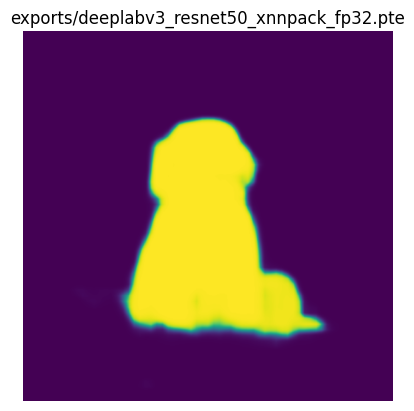

[program.cpp:154] InternalConsistency verification requested but not available


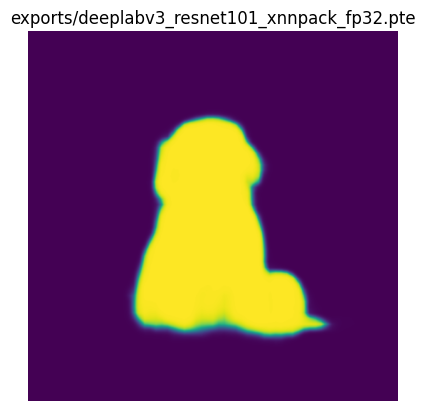

[program.cpp:154] InternalConsistency verification requested but not available


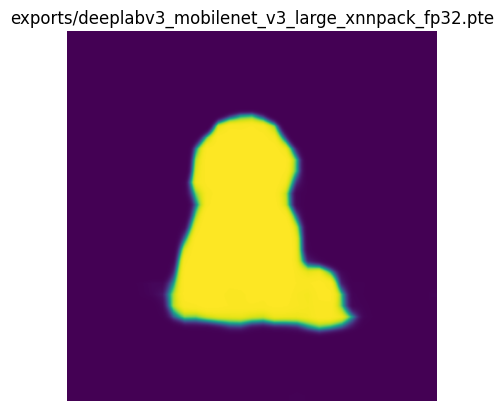

[program.cpp:154] InternalConsistency verification requested but not available


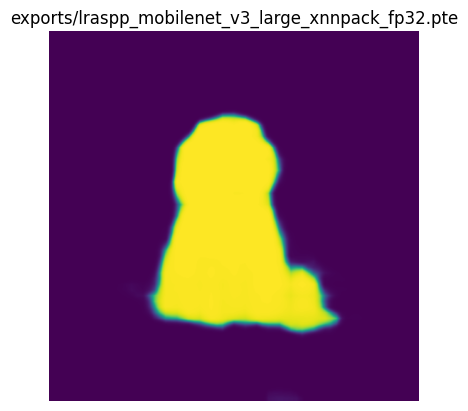

[program.cpp:154] InternalConsistency verification requested but not available


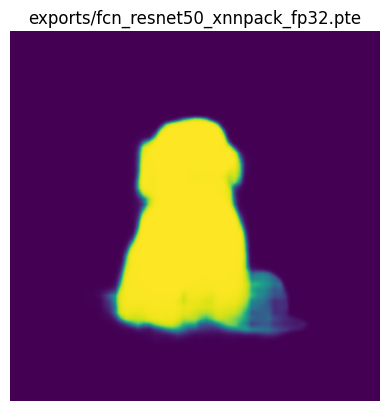

[program.cpp:154] InternalConsistency verification requested but not available


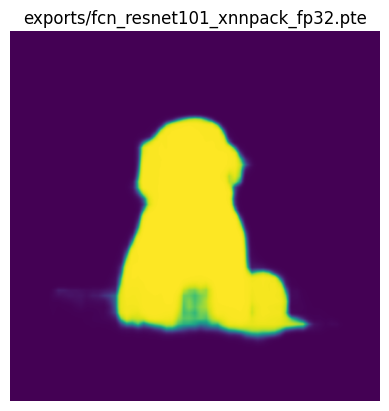

In [14]:
print("Visual inspection...")

img = decode_image("assets/dog.png")
plt.imshow(F.to_pil_image(img))
plt.axis("off")
plt.show()

for constructor in model_constructors:
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = preprocess(img)

    path = MODEL_PATH[constructor.__name__]
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output, *_ = program.load_method("forward").execute([img])

    normalized_masks = output.softmax(dim=1)
    class_to_idx = {cls: idx for (idx, cls) in enumerate(weights.meta["categories"])}
    mask = normalized_masks[0, class_to_idx["dog"], ...]

    plt.imshow(mask.numpy(), vmin=0, vmax=1)
    plt.title(path)
    plt.axis("off")
    plt.show()